# 🏠 House Price Prediction — End-to-End ML Project
**By: Siddharth Rajak**

### Project Goals:
- Explore and understand the dataset
- Clean and preprocess the data
- Train multiple ML models
- Compare and evaluate models
- Save the best model for deployment

### Dataset: California Housing Dataset (built into sklearn — no download needed!)

---
## 📦 Step 1 — Import Libraries

In [2]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Dataset
from sklearn.datasets import fetch_california_housing

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Save model
import joblib

print('✅ All libraries imported successfully!')
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)

✅ All libraries imported successfully!
NumPy: 2.3.5
Pandas: 2.3.3


---
## 📂 Step 2 — Load the Dataset

In [3]:
# Load California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Create DataFrame
df = housing.frame

print('✅ Dataset loaded!')
print(f'Shape: {df.shape[0]} rows × {df.shape[1]} columns')
df.head()

✅ Dataset loaded!
Shape: 20640 rows × 9 columns


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
# What do the columns mean?
print('📋 Feature Descriptions:')
print('─' * 50)
for name, desc in zip(housing.feature_names, housing.feature_names):
    print(f'  {name}')
print('  MedHouseVal → TARGET (Median House Value in $100,000s)')

📋 Feature Descriptions:
──────────────────────────────────────────────────
  MedInc
  HouseAge
  AveRooms
  AveBedrms
  Population
  AveOccup
  Latitude
  Longitude
  MedHouseVal → TARGET (Median House Value in $100,000s)


---
## 🔍 Step 3 — Exploratory Data Analysis (EDA)

In [5]:
# Basic statistics
print('📊 Basic Statistics:')
df.describe().round(2)

📊 Basic Statistics:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


In [6]:
# Check for missing values
print('🔍 Missing Values:')
missing = df.isnull().sum()
print(missing)
print(f'\n✅ Total missing values: {missing.sum()}')

🔍 Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

✅ Total missing values: 0


FileNotFoundError: [Errno 2] No such file or directory: 'plots/01_price_distribution.png'

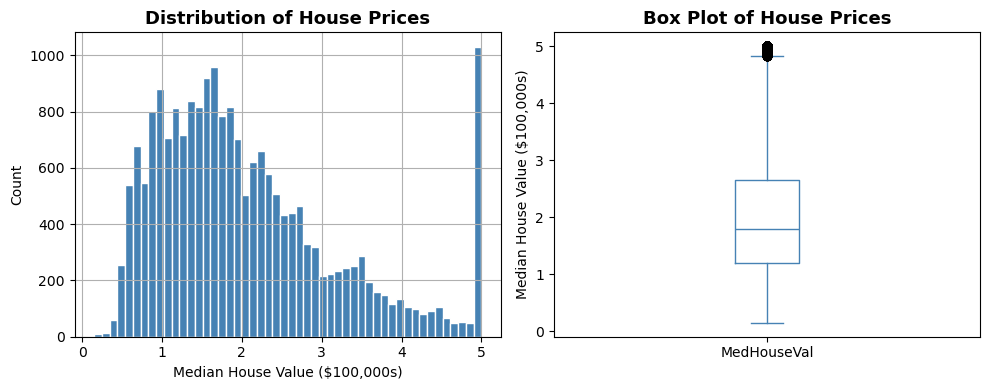

In [7]:
# Distribution of Target Variable
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
df['MedHouseVal'].hist(bins=50, color='steelblue', edgecolor='white')
plt.title('Distribution of House Prices', fontsize=13, fontweight='bold')
plt.xlabel('Median House Value ($100,000s)')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
df['MedHouseVal'].plot(kind='box', color='steelblue')
plt.title('Box Plot of House Prices', fontsize=13, fontweight='bold')
plt.ylabel('Median House Value ($100,000s)')

plt.tight_layout()
plt.savefig('plots/01_price_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Plot saved!')

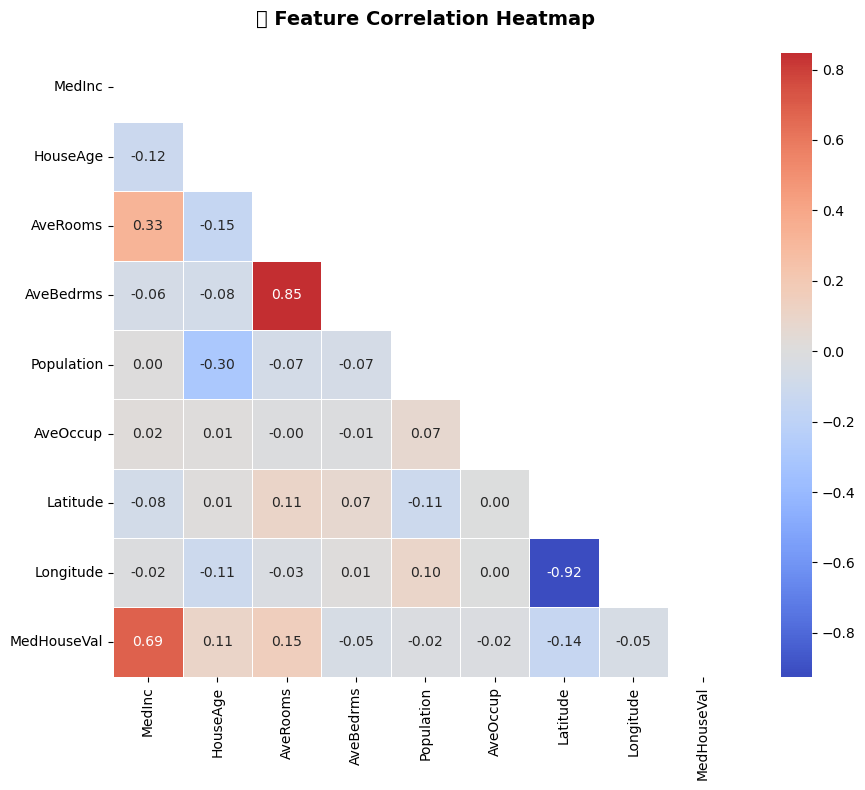

✅ Heatmap saved!

💡 Key Insight: MedInc (Median Income) has the strongest correlation with house price!


In [8]:
import os
os.makedirs('plots', exist_ok=True)

# Correlation Heatmap
plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5
)
plt.title('🔥 Feature Correlation Heatmap', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('plots/02_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Heatmap saved!')
print('\n💡 Key Insight: MedInc (Median Income) has the strongest correlation with house price!')

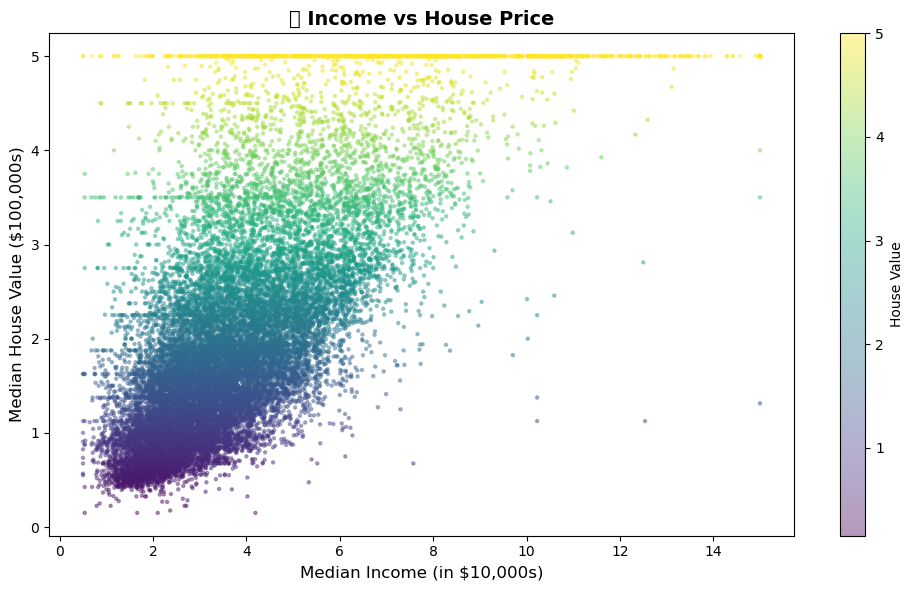

In [9]:
# Income vs House Price scatter
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    df['MedInc'], df['MedHouseVal'],
    c=df['MedHouseVal'], cmap='viridis',
    alpha=0.4, s=5
)
plt.colorbar(scatter, label='House Value')
plt.xlabel('Median Income (in $10,000s)', fontsize=12)
plt.ylabel('Median House Value ($100,000s)', fontsize=12)
plt.title('💰 Income vs House Price', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/03_income_vs_price.png', dpi=150, bbox_inches='tight')
plt.show()

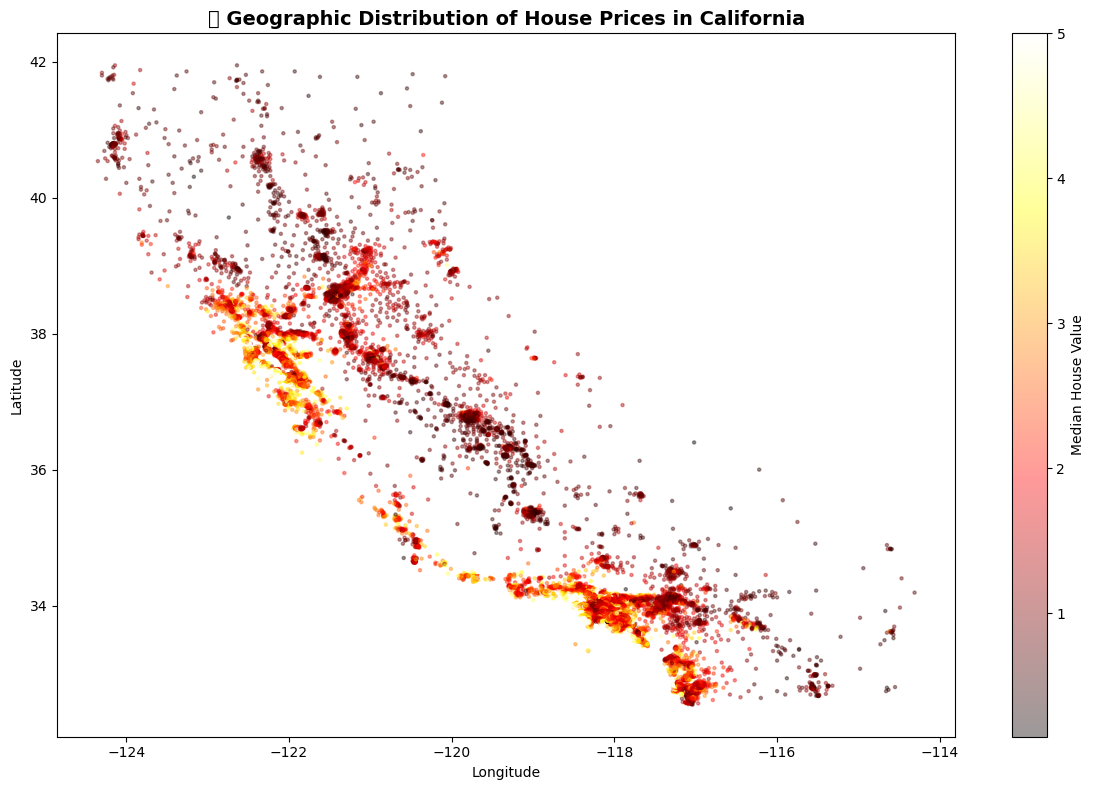

💡 Key Insight: Coastal areas (LA, SF) have much higher prices!


In [10]:
# Geographic distribution of house prices
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    df['Longitude'], df['Latitude'],
    c=df['MedHouseVal'], cmap='hot',
    alpha=0.4, s=5
)
plt.colorbar(scatter, label='Median House Value')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('🗺️ Geographic Distribution of House Prices in California', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/04_geo_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('💡 Key Insight: Coastal areas (LA, SF) have much higher prices!')

---
## 🧹 Step 4 — Data Preprocessing

In [11]:
# Separate features and target
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

print(f'Features shape: {X.shape}')
print(f'Target shape: {y.shape}')
print(f'\nFeatures: {list(X.columns)}')

Features shape: (20640, 8)
Target shape: (20640,)

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [12]:
# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'✅ Train size: {X_train.shape[0]} samples')
print(f'✅ Test size:  {X_test.shape[0]} samples')

✅ Train size: 16512 samples
✅ Test size:  4128 samples


In [13]:
# Feature Scaling (important for Linear Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('✅ Features scaled using StandardScaler')
print('   Mean ≈ 0, Std ≈ 1 for all features now')

✅ Features scaled using StandardScaler
   Mean ≈ 0, Std ≈ 1 for all features now


---
## 🤖 Step 5 — Train Multiple Models

In [14]:
# Define all models to compare
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42)
}

# Store results
results = []

print('🤖 Training models...\n')
print(f'{"Model":<25} {"R² Score":>10} {"RMSE":>10} {"MAE":>10}')
print('─' * 60)

for name, model in models.items():
    # Use scaled data for Linear Regression, raw for tree-based
    if name == 'Linear Regression':
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    r2  = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae  = mean_absolute_error(y_test, y_pred)

    results.append({'Model': name, 'R2_Score': r2, 'RMSE': rmse, 'MAE': mae})
    print(f'{name:<25} {r2:>10.4f} {rmse:>10.4f} {mae:>10.4f}')

print('─' * 60)
print('\n✅ All models trained!')

🤖 Training models...

Model                       R² Score       RMSE        MAE
────────────────────────────────────────────────────────────
Linear Regression             0.5758     0.7456     0.5332
Decision Tree                 0.6187     0.7069     0.4558
Random Forest                 0.8049     0.5057     0.3276
Gradient Boosting             0.7756     0.5422     0.3716
────────────────────────────────────────────────────────────

✅ All models trained!


---
## 📊 Step 6 — Compare & Evaluate Models

In [15]:
results_df = pd.DataFrame(results).sort_values('R2_Score', ascending=False)
print('🏆 Model Ranking by R² Score:')
results_df

🏆 Model Ranking by R² Score:


,Model,R2_Score,RMSE,MAE
2,Random Forest,0.804850,0.505694,0.327599
3,Gradient Boosting,0.775645,0.542215,0.371643
1,Decision Tree,0.618663,0.706900,0.455762
0,Linear Regression,0.575788,0.745581,0.533200


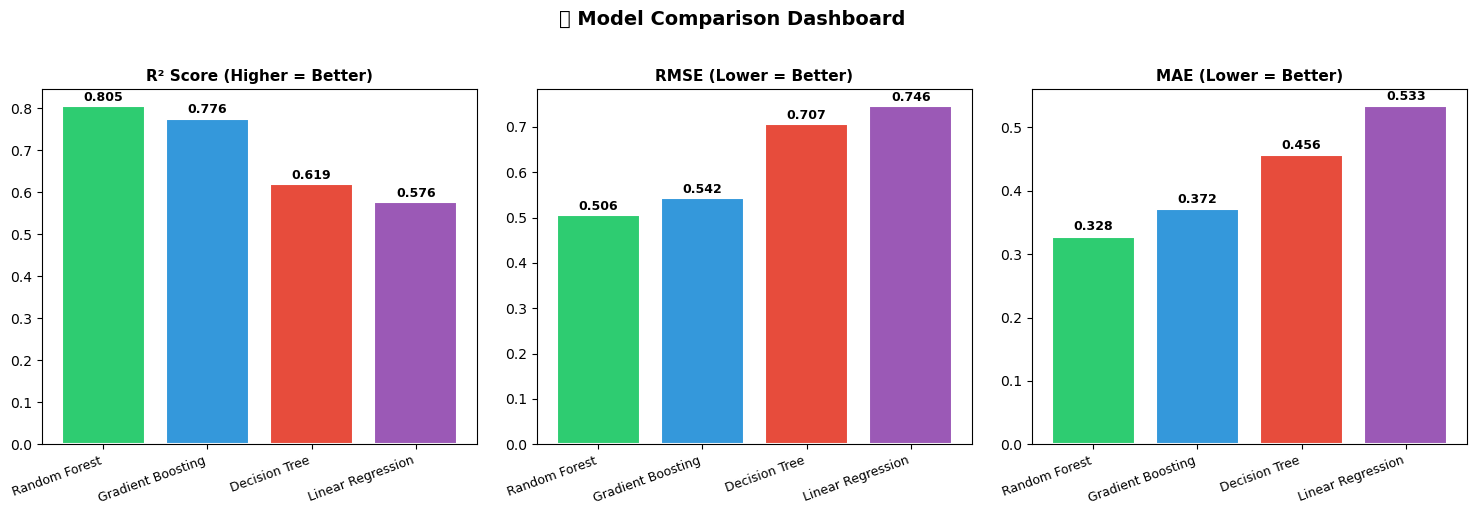

In [16]:
# Visualize model comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6']

metrics = ['R2_Score', 'RMSE', 'MAE']
titles = ['R² Score (Higher = Better)', 'RMSE (Lower = Better)', 'MAE (Lower = Better)']

for ax, metric, title in zip(axes, metrics, titles):
    bars = ax.bar(results_df['Model'], results_df[metric], color=colors, edgecolor='white', linewidth=1.5)
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_xticklabels(results_df['Model'], rotation=20, ha='right', fontsize=9)
    for bar, val in zip(bars, results_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('🤖 Model Comparison Dashboard', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plots/05_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

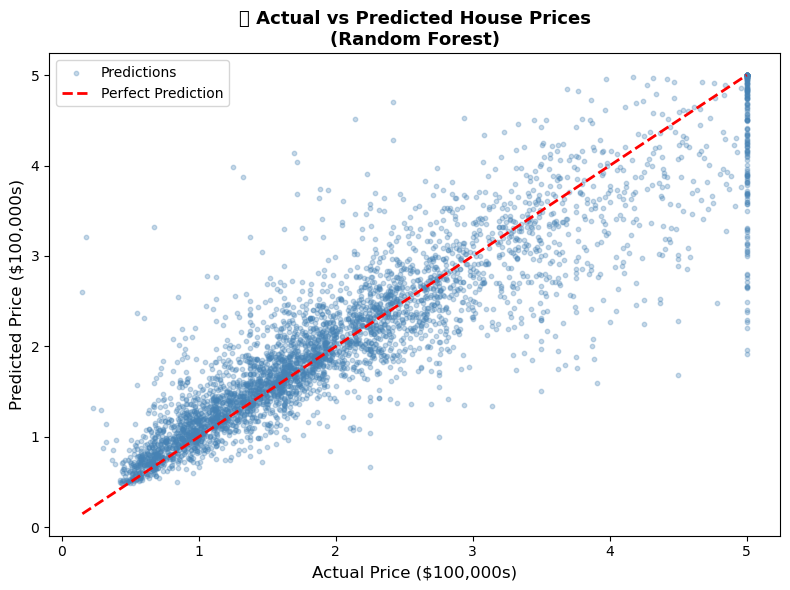

In [17]:
# Best model: Random Forest
best_model = models['Random Forest']
y_pred_best = best_model.predict(X_test)

# Actual vs Predicted plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.3, color='steelblue', s=10, label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Price ($100,000s)', fontsize=12)
plt.ylabel('Predicted Price ($100,000s)', fontsize=12)
plt.title('🎯 Actual vs Predicted House Prices\n(Random Forest)', fontsize=13, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig('plots/06_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

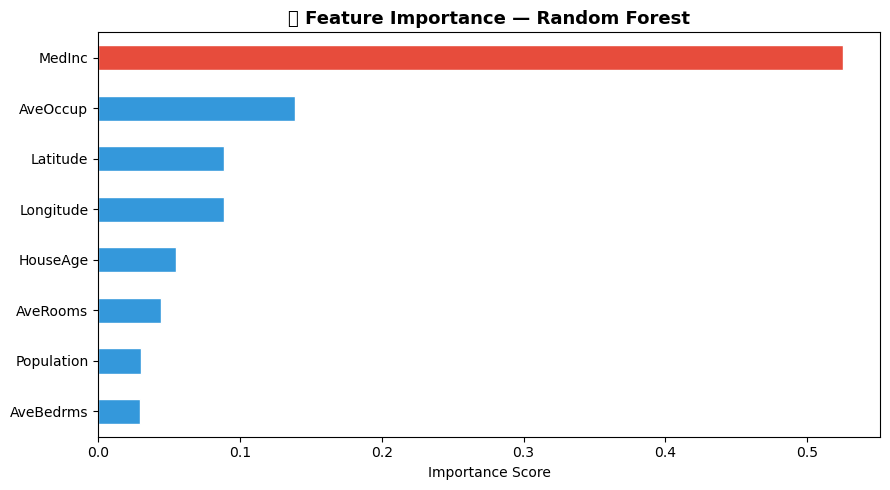


🏆 Most Important Feature: MedInc
💡 This makes sense — income is the strongest predictor of house price!


In [18]:
# Feature Importance
feature_importance = pd.Series(
    best_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
colors_fi = ['#e74c3c' if x == feature_importance.max() else '#3498db' for x in feature_importance]
feature_importance.plot(kind='barh', color=colors_fi, edgecolor='white')
plt.title('🔑 Feature Importance — Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.savefig('plots/07_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\n🏆 Most Important Feature: {feature_importance.idxmax()}')
print('💡 This makes sense — income is the strongest predictor of house price!')

---
## 💾 Step 7 — Save the Best Model

In [19]:
import os
os.makedirs('model', exist_ok=True)

# Save model and scaler
joblib.dump(best_model, 'model/house_price_model.pkl')
joblib.dump(scaler, 'model/scaler.pkl')

print('✅ Model saved to: model/house_price_model.pkl')
print('✅ Scaler saved to: model/scaler.pkl')

✅ Model saved to: model/house_price_model.pkl
✅ Scaler saved to: model/scaler.pkl


---
## 🎉 Step 8 — Final Summary

In [20]:
best_r2   = results_df.iloc[0]['R2_Score']
best_rmse = results_df.iloc[0]['RMSE']
best_mae  = results_df.iloc[0]['MAE']
best_name = results_df.iloc[0]['Model']

print('=' * 55)
print('        🏠 HOUSE PRICE PREDICTION — RESULTS')
print('=' * 55)
print(f'  Best Model    : {best_name}')
print(f'  R² Score      : {best_r2:.4f} ({best_r2*100:.1f}% variance explained)')
print(f'  RMSE          : ${best_rmse*100000:,.0f}')
print(f'  MAE           : ${best_mae*100000:,.0f}')
print('─' * 55)
print(f'  Key Finding   : Median Income is the #1 predictor')
print(f'  Dataset Size  : {len(df):,} California housing blocks')
print('=' * 55)
print('\n✅ Project Complete! Ready to build Streamlit app.')

        🏠 HOUSE PRICE PREDICTION — RESULTS
  Best Model    : Random Forest
  R² Score      : 0.8049 (80.5% variance explained)
  RMSE          : $50,569
  MAE           : $32,760
───────────────────────────────────────────────────────
  Key Finding   : Median Income is the #1 predictor
  Dataset Size  : 20,640 California housing blocks

✅ Project Complete! Ready to build Streamlit app.
